Episode 200 | Steps = 13 | Reward = 76.0 | Epsilon = 0.367
Episode 400 | Steps = 14 | Reward = 87.0 | Epsilon = 0.135
Episode 600 | Steps = 12 | Reward = 89.0 | Epsilon = 0.050
Episode 800 | Steps = 10 | Reward = 91.0 | Epsilon = 0.050
Episode 1000 | Steps = 10 | Reward = 91.0 | Epsilon = 0.050

Learned Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (2, 5), (3, 5), (4, 5), (5, 5)]
Number of Steps: 10

Best Action in Each Free Cell:
Right Right Down  ##### Down  Left 
##### ##### Down  ##### Down  #####
Right Right Right Right Right Down 
Down  ##### ##### ##### ##### Down 
Right Right Right Down  ##### Down 
##### ##### ##### Right Right GOAL 


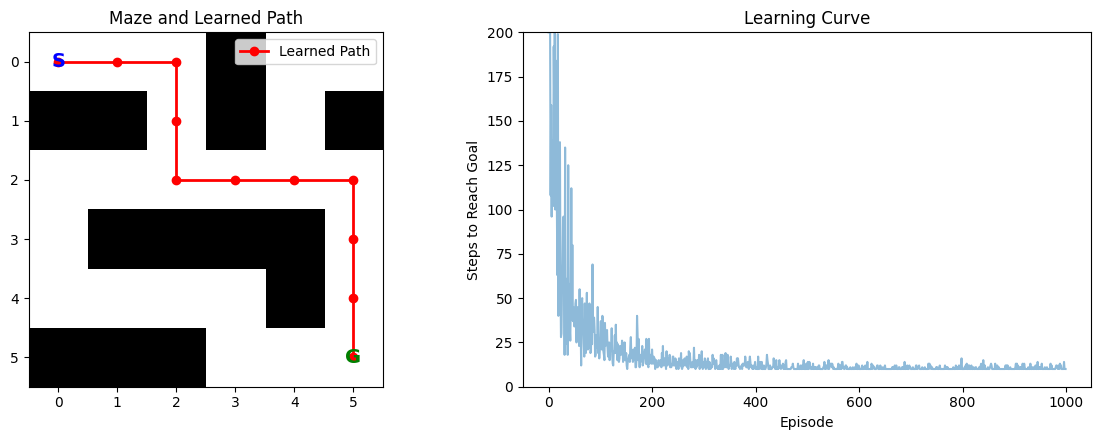

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

np.random.seed(42)

# 1. Maze environment (0 = free cell, 1 = wall)

maze = np.array([
    [0, 0, 0, 1, 0, 0],
    [1, 1, 0, 1, 0, 1],
    [0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 1, 0],
    [1, 1, 1, 0, 0, 0]
])

rows, cols = maze.shape

start = (0, 0)
goal = (5, 5)

actions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
action_names = ['Up', 'Down', 'Left', 'Right']

GOAL_REWARD = 100
STEP_REWARD = -1
WALL_REWARD = -5


# 2. Environment function

def step(state, action):
    r, c = state
    dr, dc = actions[action]

    nr = r + dr
    nc = c + dc

    # Check boundaries and walls
    if nr < 0 or nr >= rows or nc < 0 or nc >= cols or maze[nr, nc] == 1:
        return state, WALL_REWARD, False

    # Check goal
    if (nr, nc) == goal:
        return (nr, nc), GOAL_REWARD, True

    return (nr, nc), STEP_REWARD, False


# 3. Q-learning parameters

alpha = 0.1
gamma = 0.9

epsilon = 1.0
eps_min = 0.05
eps_decay = 0.995

episodes = 1000
max_steps = 200

Q = np.zeros((rows, cols, len(actions)))

steps_per_episode = []
reward_per_episode = []


# 4. Training

for ep in range(episodes):

    state = start
    total_reward = 0

    for t in range(max_steps):

        # Epsilon-greedy action selection
        if np.random.rand() < epsilon:
            action = np.random.randint(len(actions))
        else:
            action = np.argmax(Q[state[0], state[1]])

        next_state, reward, done = step(state, action)

        # Q-learning update
        best_next = np.max(Q[next_state[0], next_state[1]])

        Q[state[0], state[1], action] += alpha * (
            reward + gamma * best_next - Q[state[0], state[1], action]
        )

        state = next_state
        total_reward += reward

        if done:
            break

    # Reduce exploration
    epsilon = max(eps_min, epsilon * eps_decay)

    steps_per_episode.append(t + 1)
    reward_per_episode.append(total_reward)

    if (ep + 1) % 200 == 0:
        print(f"Episode {ep + 1} | Steps = {t + 1} | Reward = {total_reward:.1f} | Epsilon = {epsilon:.3f}")


# 5. Extract learned path

state = start
path = [start]
visited = {start}

while state != goal and len(path) < 50:

    action = np.argmax(Q[state[0], state[1]])
    next_state, reward, done = step(state, action)

    # Stop if the agent gets stuck in a loop
    if next_state in visited:
        break

    state = next_state
    path.append(state)
    visited.add(state)

print("\nLearned Path:", path)
print("Number of Steps:", len(path) - 1)


# 6. Best action in each free cell

print("\nBest Action in Each Free Cell:")

for r in range(rows):
    row = []

    for c in range(cols):
        if maze[r, c] == 1:
            row.append("#####")
        elif (r, c) == goal:
            row.append("GOAL")
        else:
            best_action = np.argmax(Q[r, c])
            row.append(action_names[best_action])

    print(" ".join(f"{cell:<5}" for cell in row))


# 7. Visualizations

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Maze and learned path
ax[0].imshow(maze, cmap=ListedColormap(['white', 'black']))

ys, xs = zip(*path)
ax[0].plot(xs, ys, 'r-o', linewidth=2, label='Learned Path')

ax[0].text(start[1], start[0], 'S', color='blue',
           ha='center', va='center', fontsize=14, fontweight='bold')

ax[0].text(goal[1], goal[0], 'G', color='green',
           ha='center', va='center', fontsize=14, fontweight='bold')

ax[0].set_title('Maze and Learned Path')
ax[0].legend()

ax[0].set_xticks(range(cols))
ax[0].set_yticks(range(rows))


# Learning curve
ax[1].plot(steps_per_episode, alpha=0.5)

ax[1].set_xlabel('Episode')
ax[1].set_ylabel('Steps to Reach Goal')
ax[1].set_title('Learning Curve')
ax[1].set_ylim(0, 200)

plt.tight_layout()
plt.show()